# Step 4 — Is it still the same strategy?

Above eight players nothing can compute the right answer, so the agent at 10 and 15 players cannot
be checked against one. It can be checked against **itself**, across the range where it *was*
checked.

The comparison is made at the **same number of players left**. A game that starts with fifteen
players eventually has seven left, then five, then three. If the agent at that moment behaves the
way the seven-player agent behaves with the same number left, it is following a rule about its
position in the game rather than about how large the game started. If it behaves differently, the
starting size has changed what it learned.

Neither answer needs an exact solution, because both sides of the comparison are measurements of
this project's own agent.

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from gruel_env import GruelEnv, N_ACTIONS, MISS, SHOOT_LEFT, SHOOT_RIGHT

torch.set_num_threads(1)
print("torch", torch.__version__)

torch 2.2.2


## Settings

All five player counts, trained exactly as in step 1. Three, five and seven are the counts where
the exact answer is known; ten and fifteen are where it is not.

In [2]:
PLAYER_COUNTS = [3, 5, 7, 10, 15]
CHECKED = [3, 5, 7]
UNCHECKED = [10, 15]
REWARD = "terminal"
SEATING = "ranked"

OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64

UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
SEEDS = [0, 1, 2]

LEARNING_RATE = 0.003
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01

AGREE_THRESHOLD = 0.10
REFERENCE_EPISODES = 10000

print("player counts:", PLAYER_COUNTS, " checked against an exact answer:", CHECKED)
print("two measurements agree if they differ by at most %.2f" % AGREE_THRESHOLD)

player counts: [3, 5, 7, 10, 15]  checked against an exact answer: [3, 5, 7]
two measurements agree if they differ by at most 0.10


## The measurement

The share of eligible decisions in which the shooter fired at its stronger neighbour, broken down
by how many players were left at the time. A decision is eligible only if the player fired, more
than two players were left, and its two neighbours differed in strength. With three players left
the measurement always exists; with two it never does, because both neighbours are the same
player.

The exact equilibrium's values, from folder 02 step 5, are shown where they exist.

In [3]:
EXACT_BY_ALIVE = {
    3: {3: 1.0000},
    5: {5: 0.4000, 4: 0.5000, 3: 1.0000},
    7: {7: 0.1429, 6: 0.4517, 5: 0.4000, 4: 0.5000, 3: 1.0000},
}
for n in sorted(EXACT_BY_ALIVE):
    row = []
    for alive_count in sorted(EXACT_BY_ALIVE[n], reverse=True):
        row.append("%d left %.4f" % (alive_count, EXACT_BY_ALIVE[n][alive_count]))
    print("  exact, N=%d:  %s" % (n, "   ".join(row)))

  exact, N=3:  3 left 1.0000
  exact, N=5:  5 left 0.4000   4 left 0.5000   3 left 1.0000
  exact, N=7:  7 left 0.1429   6 left 0.4517   5 left 0.4000   4 left 0.5000   3 left 1.0000


## The agent, its training and the targeting measurement, copied forward

The agent and its training are step 1's, unchanged; the targeting functions are deliverable
03's, unchanged. Rule 1 says a step copies earlier code forward rather than importing it, so
this folder carries its own copy and can be handed over on its own.

In [4]:
class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector


def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}
        # What each player had already banked when it made each decision. Needed because
        # the return for a decision is whatever arrives AFTER it, and under `shaped`
        # rewards arrive throughout the episode rather than only at the end.
        episode_banked_before = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            banked_so_far = float(game.episode_returns[acting_agent])
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)
            episode_banked_before[actor].append(banked_so_far)

            game.step(int(action))

        for position in range(game.n):
            # The return for a decision is the reward-to-go: everything this player ended
            # the episode with, minus what it had already banked when it decided. With a
            # discount of 1 that is exactly the undiscounted sum of what came after.
            #
            # Reading it from the environment is the whole point of this step. Assuming
            # `1.0 for the winner, 0.0 for everyone else` is correct under `terminal` and
            # silently WRONG under `shaped`, where it would discard every kill bonus,
            # every elimination penalty and every survival tick -- and both arms would then
            # train on identical numbers and look identical for a reason that is a bug.
            name = game.agent_of_position[position]
            final_total = float(game.episode_returns[name])
            for index in range(len(episode_actions[position])):
                own_return = final_total - episode_banked_before[position][index]
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()


def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy


def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "hit_cap": game.reason == "hard_cap",
            "decisions": decisions,
        })
    return records


def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other


def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions


def next_weaker(game, actor):
    """Archetti's rule on the circle: the strongest neighbour still weaker than you, else the stronger."""
    left, right = game.neighbours(actor)
    mine = game.accuracies[actor]
    pool = []
    for candidate in (left, right):
        if game.accuracies[candidate] < mine:
            pool.append(candidate)
    if len(pool) == 0:
        pool = [left, right]      # both outgun you: you are the weak one, so fire at the stronger
    target = pool[0]
    for candidate in pool:
        if game.accuracies[candidate] > game.accuracies[target]:
            target = candidate
    if target == left:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def accuracies_of(n):
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=0)
    game.reset(seed=0)
    return [round(float(a), 4) for a in game.accuracies]


def train_one(n, seed):
    torch.manual_seed(2000 + seed)
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=1000 + seed)
    model = SharedActorCritic(n_players=n)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(model, game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)
    return model


def measure(model, n, seed):
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=5000 + seed)
    torch.manual_seed(7000 + seed)
    return play_episodes(game, make_agent_policy(model), EVALUATION_EPISODES)


def targeting_by_alive(records):
    stronger_count = {}
    decision_count = {}
    for record in records:
        for decision in record["decisions"]:
            if not eligible(decision):
                continue
            alive_then = decision["n_alive"]
            if alive_then not in decision_count:
                stronger_count[alive_then] = 0
                decision_count[alive_then] = 0
            decision_count[alive_then] = decision_count[alive_then] + 1
            if chose_stronger(decision):
                stronger_count[alive_then] = stronger_count[alive_then] + 1
    rows = {}
    for alive in sorted(decision_count):
        rows[alive] = (stronger_count[alive] / decision_count[alive],
                       stronger_count[alive],
                       decision_count[alive])
    return rows

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [5]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step4_continuity.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

## Training and measuring

In [6]:
TRAINED = {}
RECORDS = {}
started_all = time.time()
for n in PLAYER_COUNTS:
    TRAINED[n] = {}
    RECORDS[n] = {}
    for seed in SEEDS:
        started = time.time()
        TRAINED[n][seed] = train_one(n, seed)
        save_model(TRAINED[n][seed], run_key(n, SEATING, REWARD, "centralised", UPDATES, seed),
                   mappo_settings(n, REWARD, SEATING, seed, UPDATES, EPISODES_PER_UPDATE,
                                  "centralised", time.time() - started, "training only"))
        RECORDS[n][seed] = measure(TRAINED[n][seed], n, seed)
        print("  N=%-3d seed %d trained and measured in %4.1f min"
              % (n, seed, (time.time() - started) / 60.0), flush=True)
print("  total %.1f min" % ((time.time() - started_all) / 60.0))

  N=3   seed 0 trained and measured in  1.1 min


  N=3   seed 1 trained and measured in  1.3 min


  N=3   seed 2 trained and measured in  1.5 min


  N=5   seed 0 trained and measured in  2.8 min


  N=5   seed 1 trained and measured in  2.9 min


  N=5   seed 2 trained and measured in  3.1 min


... (6 outputs left out)

  N=15  seed 0 trained and measured in  9.5 min


  N=15  seed 1 trained and measured in  9.8 min


  N=15  seed 2 trained and measured in  9.5 min


  total 71.2 min


## Targeting by players left, for every starting size

Rows are the number of players left; columns are the size the game started at. Each cell pools the
three seeds. The spread across seeds is shown alongside, because an agreement smaller than the
disagreement between seeds of the *same* size means nothing.

In [7]:
BY_ALIVE = {}
SPREAD = {}
for n in PLAYER_COUNTS:
    combined = []
    for seed in SEEDS:
        combined.extend(RECORDS[n][seed])
    pooled_rows = targeting_by_alive(combined)
    BY_ALIVE[n] = {}
    SPREAD[n] = {}
    per_seed_rows = []
    for seed in SEEDS:
        per_seed_rows.append(targeting_by_alive(RECORDS[n][seed]))
    for alive_count in pooled_rows:
        BY_ALIVE[n][alive_count] = pooled_rows[alive_count][0]
        seed_values = []
        for rows in per_seed_rows:
            if alive_count in rows:
                seed_values.append(rows[alive_count][0])
        SPREAD[n][alive_count] = max(seed_values) - min(seed_values)

largest = PLAYER_COUNTS[-1]
header = "  left  " + "".join("   N=%-9d" % n for n in PLAYER_COUNTS)
print(header)
for alive_count in range(largest, 2, -1):
    cells = []
    for n in PLAYER_COUNTS:
        if alive_count in BY_ALIVE[n]:
            cells.append("  %.4f ±%.2f" % (BY_ALIVE[n][alive_count], SPREAD[n][alive_count] / 2))
        else:
            cells.append("        -   ")
    print("  %4d  %s" % (alive_count, "".join(cells)))
print()
print("  (± is half the range across the three seeds)")

  left     N=3           N=5           N=7           N=10          N=15       
    15          -           -           -           -     0.1294 ±0.01
    14          -           -           -           -     0.1421 ±0.01
    13          -           -           -           -     0.1532 ±0.00
    12          -           -           -           -     0.1682 ±0.00
    11          -           -           -           -     0.1809 ±0.00
    10          -           -           -     0.1978 ±0.00  0.1996 ±0.00
     9          -           -           -     0.2226 ±0.00  0.2268 ±0.00
     8          -           -           -     0.2497 ±0.00  0.2496 ±0.01
     7          -           -     0.2822 ±0.00  0.2861 ±0.01  0.2830 ±0.00
     6          -           -     0.3338 ±0.00  0.3328 ±0.00  0.3333 ±0.00
     5          -     0.3991 ±0.00  0.3976 ±0.00  0.4026 ±0.00  0.4168 ±0.03
     4          -     0.5159 ±0.01  0.5075 ±0.01  0.5624 ±0.05  0.5922 ±0.10
     3    0.9983 ±0.00  0.9777 ±0.01  0.842

## A fixed rule that already rises as the circle contracts

Step 3 measured `next_weaker`, Archetti's rule restricted to the two neighbours, and found that
under `ranked` seating it is the same as always shooting left. With $k$ players left it shoots the
stronger neighbour at exactly two of the $k$ seats, the weakest and the strongest, so its value in
this table is $2/k$ whatever size the game started at. **A curve that rises as players are
eliminated, and that is the same for every starting size, is therefore what a fixed rule with no
knowledge of the starting size produces.** Agreement between sizes only says something about the
agent at the counts where the agent is *not* close to `next_weaker`.

In [8]:
NEXT_WEAKER_BY_ALIVE = {}
for n in PLAYER_COUNTS:
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=7000 + n)
    rows = targeting_by_alive(play_episodes(game, next_weaker, REFERENCE_EPISODES))
    NEXT_WEAKER_BY_ALIVE[n] = {}
    for alive_count in rows:
        NEXT_WEAKER_BY_ALIVE[n][alive_count] = rows[alive_count][0]

print("  left   2/k      next_weaker, by starting size          agent minus next_weaker, by starting size")
for alive_count in range(largest, 2, -1):
    measured = []
    differences = []
    for n in PLAYER_COUNTS:
        if alive_count in NEXT_WEAKER_BY_ALIVE[n]:
            measured.append("%.4f" % NEXT_WEAKER_BY_ALIVE[n][alive_count])
            differences.append("%+.4f" % (BY_ALIVE[n][alive_count] - NEXT_WEAKER_BY_ALIVE[n][alive_count]))
        else:
            measured.append("   -  ")
            differences.append("   -   ")
    print("  %4d  %.4f   %s   %s" % (alive_count, 2.0 / alive_count, " ".join(measured), " ".join(differences)))

  left   2/k      next_weaker, by starting size          agent minus next_weaker, by starting size
    15  0.1333      -      -      -      -   0.1310      -       -       -       -    -0.0016
    14  0.1429      -      -      -      -   0.1430      -       -       -       -    -0.0009
    13  0.1538      -      -      -      -   0.1543      -       -       -       -    -0.0010
    12  0.1667      -      -      -      -   0.1647      -       -       -       -    +0.0035
    11  0.1818      -      -      -      -   0.1811      -       -       -       -    -0.0003
    10  0.2000      -      -      -   0.2039 0.1965      -       -       -    -0.0061 +0.0031
     9  0.2222      -      -      -   0.2207 0.2199      -       -       -    +0.0020 +0.0069
     8  0.2500      -      -      -   0.2511 0.2448      -       -       -    -0.0014 +0.0049
     7  0.2857      -      -   0.2847 0.2845 0.2894      -       -    -0.0025 +0.0016 -0.0064
     6  0.3333      -      -   0.3326 0.3398 0.3331    

## Where the truth is known: does the agent match it?

Before comparing sizes with each other, check each checked size against its own exact answer.
Continuity is only worth something if the range it is continuous *with* was right.

In [9]:
CHECKED_GAP = {}
for n in CHECKED:
    worst = 0.0
    row = []
    for alive_count in sorted(EXACT_BY_ALIVE[n], reverse=True):
        gap = abs(BY_ALIVE[n][alive_count] - EXACT_BY_ALIVE[n][alive_count])
        worst = max(worst, gap)
        row.append("%d left %.4f vs %.4f" % (alive_count, BY_ALIVE[n][alive_count], EXACT_BY_ALIVE[n][alive_count]))
    CHECKED_GAP[n] = worst
    verdict = "matches" if worst <= AGREE_THRESHOLD else "does NOT match"
    print("  N=%d  %s" % (n, "   ".join(row)))
    print("        worst gap %.4f -> %s the exact answer" % (worst, verdict))
    print()

  N=3  3 left 0.9983 vs 1.0000
        worst gap 0.0017 -> matches the exact answer

  N=5  5 left 0.3991 vs 0.4000   4 left 0.5159 vs 0.5000   3 left 0.9777 vs 1.0000
        worst gap 0.0223 -> matches the exact answer

  N=7  7 left 0.2822 vs 0.1429   6 left 0.3338 vs 0.4517   5 left 0.3976 vs 0.4000   4 left 0.5075 vs 0.5000   3 left 0.8426 vs 1.0000
        worst gap 0.1574 -> does NOT match the exact answer



## The comparison: each unchecked size against the largest checked one

The largest checked size is seven players. At every number of players left that both games pass
through, compare the unchecked agent with the seven-player agent.

In [10]:
reference_size = CHECKED[-1]
AGREEMENT = {}
for n in UNCHECKED:
    shared = []
    for alive_count in sorted(BY_ALIVE[reference_size], reverse=True):
        if alive_count in BY_ALIVE[n]:
            shared.append(alive_count)
    agreeing = []
    informative = []
    print("  N=%d against N=%d, at the same number of players left" % (n, reference_size))
    for alive_count in shared:
        gap = abs(BY_ALIVE[n][alive_count] - BY_ALIVE[reference_size][alive_count])
        agrees = gap <= AGREE_THRESHOLD
        if agrees:
            agreeing.append(alive_count)
        # A count is informative only if at least one of the two agents is away from next_weaker;
        # otherwise both sides agree because both are close to the same fixed rule.
        off_rule = max(abs(BY_ALIVE[n][alive_count] - NEXT_WEAKER_BY_ALIVE[n][alive_count]),
                       abs(BY_ALIVE[reference_size][alive_count]
                           - NEXT_WEAKER_BY_ALIVE[reference_size][alive_count]))
        if off_rule > AGREE_THRESHOLD:
            informative.append(alive_count)
            note = "away from next_weaker by %.4f" % off_rule
        else:
            note = "both within %.4f of next_weaker" % off_rule
        print("    %d left   N=%d %.4f   N=%d %.4f   gap %.4f   %-6s  %s"
              % (alive_count, n, BY_ALIVE[n][alive_count], reference_size,
                 BY_ALIVE[reference_size][alive_count], gap, "agree" if agrees else "DIFFER", note))
    AGREEMENT[n] = (agreeing, shared, informative)
    print("    agree at %d of %d shared counts; informative counts %s" % (len(agreeing), len(shared), informative))
    print()

  N=10 against N=7, at the same number of players left
    7 left   N=10 0.2861   N=7 0.2822   gap 0.0039   agree   both within 0.0025 of next_weaker
    6 left   N=10 0.3328   N=7 0.3338   gap 0.0010   agree   both within 0.0070 of next_weaker
    5 left   N=10 0.4026   N=7 0.3976   gap 0.0050   agree   both within 0.0091 of next_weaker
    4 left   N=10 0.5624   N=7 0.5075   gap 0.0549   agree   both within 0.0583 of next_weaker
    3 left   N=10 0.9286   N=7 0.8426   gap 0.0860   agree   away from next_weaker by 0.2660
    agree at 5 of 5 shared counts; informative counts [3]

  N=15 against N=7, at the same number of players left
    7 left   N=15 0.2830   N=7 0.2822   gap 0.0007   agree   both within 0.0064 of next_weaker
    6 left   N=15 0.3333   N=7 0.3338   gap 0.0004   agree   both within 0.0012 of next_weaker
    5 left   N=15 0.4168   N=7 0.3976   gap 0.0192   agree   both within 0.0182 of next_weaker
    4 left   N=15 0.5922   N=7 0.5075   gap 0.0848   agree   both within 

## Adjacent sizes, all the way up

The same comparison between each pair of neighbouring sizes, so the point where behaviour starts
to change, if it does, can be located.

In [11]:
for index in range(1, len(PLAYER_COUNTS)):
    smaller = PLAYER_COUNTS[index - 1]
    bigger = PLAYER_COUNTS[index]
    gaps = []
    for alive_count in BY_ALIVE[smaller]:
        if alive_count in BY_ALIVE[bigger]:
            gaps.append((alive_count, abs(BY_ALIVE[bigger][alive_count] - BY_ALIVE[smaller][alive_count])))
    gaps.sort(reverse=True)
    worst_count, worst_gap = max(gaps, key=lambda pair: pair[1])
    agree_count = 0
    for alive_count, pair_gap in gaps:
        if pair_gap <= AGREE_THRESHOLD:
            agree_count = agree_count + 1
    print("  N=%-2d vs N=%-2d  shared counts %d, agree at %d, largest gap %.4f at %d left"
          % (smaller, bigger, len(gaps), agree_count, worst_gap, worst_count))

  N=3  vs N=5   shared counts 1, agree at 1, largest gap 0.0206 at 3 left
  N=5  vs N=7   shared counts 3, agree at 2, largest gap 0.1351 at 3 left
  N=7  vs N=10  shared counts 5, agree at 5, largest gap 0.0860 at 3 left
  N=10 vs N=15  shared counts 8, agree at 7, largest gap 0.1309 at 3 left


## The picture

One line per starting size. Where the lines lie on top of each other, the agent does the same
thing with that many players left however large the game began.

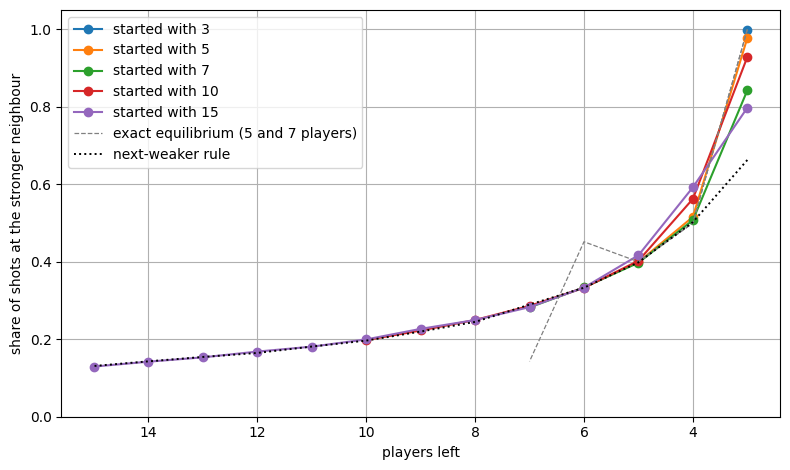

In [12]:
figure, axis = plt.subplots(figsize=(8, 4.8))
for n in PLAYER_COUNTS:
    counts = sorted(BY_ALIVE[n])
    axis.plot(counts, [BY_ALIVE[n][k] for k in counts], marker="o", label="started with %d" % n)
exact_label = "exact equilibrium (5 and 7 players)"
for n in sorted(EXACT_BY_ALIVE):
    if n == 3:
        continue
    counts = sorted(EXACT_BY_ALIVE[n])
    axis.plot(counts, [EXACT_BY_ALIVE[n][k] for k in counts], linestyle="--", color="grey",
              linewidth=0.9, label=exact_label)
    exact_label = None
counts = sorted(NEXT_WEAKER_BY_ALIVE[largest])
axis.plot(counts, [NEXT_WEAKER_BY_ALIVE[largest][k] for k in counts], linestyle=":", color="black",
          linewidth=1.4, label="next-weaker rule")
axis.set_xlabel("players left")
axis.set_ylabel("share of shots at the stronger neighbour")
axis.invert_xaxis()
axis.set_ylim(0, 1.05)
axis.grid(True)
axis.legend()
figure.tight_layout()
plt.show()

## What this establishes, derived from the measurements

In [13]:
checked_ok = []
for n in CHECKED:
    if CHECKED_GAP[n] <= AGREE_THRESHOLD:
        checked_ok.append(n)
print("  sizes that match their exact answer: %s of %s" % (checked_ok, CHECKED))
print()
for n in UNCHECKED:
    agreeing, shared, informative = AGREEMENT[n]
    informative_agreeing = [k for k in informative if k in agreeing]
    print("  N=%d agrees with N=%d at %d of %d shared counts: %s"
          % (n, reference_size, len(agreeing), len(shared), agreeing))
    print("        of those, away from next_weaker (so the agreement is about the agent): %s"
          % informative_agreeing)
print()
fully_continuous = True
for n in UNCHECKED:
    agreeing, shared, informative = AGREEMENT[n]
    if len(agreeing) != len(shared):
        fully_continuous = False
if reference_size not in checked_ok:
    print("  The seven-player agent does not match its own exact answer, so agreeing with it")
    print("  carries no guarantee of correctness. Agreement here means the agent applies the")
    print("  same rule at every size, not that the rule is right.")
if fully_continuous:
    print("  At every shared count the larger games behave like the seven-player game. Where all")
    print("  of them sit close to next_weaker, that agreement is what a fixed rule produces; the")
    print("  counts listed as away from next_weaker are the ones that say the agent itself carries")
    print("  the same departure from that rule across sizes.")
else:
    print("  The larger games do not behave like the seven-player game at every shared count, so the")
    print("  starting size changes what the agent does at the same position in the game.")

  sizes that match their exact answer: [3, 5] of [3, 5, 7]

  N=10 agrees with N=7 at 5 of 5 shared counts: [7, 6, 5, 4, 3]
        of those, away from next_weaker (so the agreement is about the agent): [3]
  N=15 agrees with N=7 at 5 of 5 shared counts: [7, 6, 5, 4, 3]
        of those, away from next_weaker (so the agreement is about the agent): [3]

  The seven-player agent does not match its own exact answer, so agreeing with it
  carries no guarantee of correctness. Agreement here means the agent applies the
  same rule at every size, not that the rule is right.
  At every shared count the larger games behave like the seven-player game. Where all
  of them sit close to next_weaker, that agreement is what a fixed rule produces; the
  counts listed as away from next_weaker are the ones that say the agent itself carries
  the same departure from that rule across sizes.


## What this does not establish

**Continuity is not correctness.** An agent can apply the same wrong rule at every size and look
perfectly continuous. And the same number of players left is not the same situation in every game:
five players left from fifteen are more closely matched in strength than five left from seven,
because the starting field was packed more tightly. So two agents behaving differently with five
left are not necessarily inconsistent; they may be responding correctly to different situations.
What this step can say is whether the behaviour checked at small sizes carries over, and where it
stops doing so.

## Reproducibility

Two random streams are reset, not one: the environment's, and torch's global stream, because a
trained policy samples its actions.

In [14]:
def measure_once():
    torch.manual_seed(7100)
    game = GruelEnv(n=PLAYER_COUNTS[-1], reward=REWARD, seating=SEATING, seed=9000)
    records = play_episodes(game, make_agent_policy(TRAINED[PLAYER_COUNTS[-1]][SEEDS[0]]), 300)
    rate, stronger, decisions = targeting_rate(records)
    return rate


first = measure_once()
second = measure_once()
print("  first  run:", format(first, ".6f"))
print("  second run:", format(second, ".6f"))
print("  identical:", first == second)

  first  run: 0.277549
  second run: 0.277549
  identical: True
